In [5]:
from pathlib import Path
import sys
import json
from itertools import islice

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))

from src.metrics.evaluator import Evaluator

In [6]:
def is_sample_valid(list_prediction: dict, list_goal: dict):
    return len(list_prediction) == len(list_goal)

In [7]:
def evaluate_valid_predictions(list_prediction: dict, list_goal: dict):
    if list_prediction.keys() != list_goal.keys():
        raise ValueError("list_prediction and list_goal must contain the same sample IDs")

    predictions = [list_prediction[sample_id] for sample_id in list_goal]
    golds = [list_goal[sample_id] for sample_id in list_goal]

    return Evaluator().evaluate_on_all_sample(predictions, golds)

In [8]:
import re
import matplotlib.pyplot as plt


def plot_checkpoint_scores(score_list: dict[str, float]):
    if not score_list:
        raise ValueError("score_list must not be empty")

    def checkpoint_number(name):
        numbers = re.findall(r"\d+", str(name))
        return int(numbers[-1]) if numbers else float("inf")

    sorted_scores = sorted(
        score_list.items(),
        key=lambda item: (checkpoint_number(item[0]), str(item[0])),
    )
    sorted_scores = sorted_scores[:10]
    checkpoints, scores = zip(*sorted_scores)
    epochs =  range(1, len(checkpoints) + 1)

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(epochs, scores, marker="o", label="Average F1")
    for epoch, score in zip(epochs, scores):
        ax.annotate(
            f"{score:.3f}",
            (epoch, score),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

    decreases = [
        epoch
        for epoch in range(len(scores) - 1)
        if scores[epoch + 1] < scores[epoch]
    ]
    for index, epoch in enumerate(decreases):
        ax.plot(
            [epoch + 1, epoch + 2],
            [scores[epoch], scores[epoch + 1]],
            color="tab:red",
            linewidth=2,
            label="Average F1 decreased" if index == 0 else "_nolegend_",
        )

    ax.set_xticks(list(epochs))
    ax.set_xticklabels(
        [f"Epoch {epoch} - CB {checkpoint_number(checkpoint)}" for epoch, checkpoint in zip(epochs, checkpoints)],
        rotation=45,
        ha="right",
    )
    ax.set_xlabel("Epoch - Checkpoint")
    ax.set_ylabel("Average F1")
    ax.set_title("Average F1 by Epoch")
    ax.grid(True, alpha=0.3)
    if decreases:
        ax.legend()
    fig.tight_layout()
    plt.show()

    return fig, ax

In [9]:
# Load goal
path = ROOT / "data" / "processed" / "GENEVA" / "dev.jsonl"

with path.open("r", encoding="utf-8") as f:
    goal = [json.loads(line) for line in f]

list_goal = {
    sample["id"]: {"events": sample["events"]}
    for sample in goal
}

print(f"Loaded {len(list_goal)} goal samples")
print(list_goal)

Loaded 766 goal samples
{'GENEVA:val:000001': {'events': [{'event_type': 'Catastrophe', 'trigger': [{'text': 'disaster', 'span': [14, 15]}], 'arguments': [{'role': 'Cause', 'mentions': [{'text': 'natural', 'span': [13, 14]}]}, {'role': 'Patient', 'mentions': [{'text': 'disaster', 'span': [14, 15]}]}]}, {'event_type': 'Creating', 'trigger': [{'text': 'establishing', 'span': [34, 35]}], 'arguments': [{'role': 'Created_entity', 'mentions': [{'text': 'interoperable communications systems and community evacuation plans', 'span': [35, 42]}]}, {'role': 'Creator', 'mentions': [{'text': 'Rhode Island', 'span': [2, 4]}]}]}, {'event_type': 'Removing', 'trigger': [{'text': 'evacuation', 'span': [40, 41]}], 'arguments': [{'role': 'Theme', 'mentions': [{'text': 'community', 'span': [39, 40]}]}]}, {'event_type': 'Communication', 'trigger': [{'text': 'communications', 'span': [36, 37]}], 'arguments': []}]}, 'GENEVA:val:000002': {'events': [{'event_type': 'Terrorism', 'trigger': [{'text': 'terrorists',

In [10]:
# Load prediction
folder_valid_results = ROOT / "model" / "Valid_OUPUT_GENEVA" / "ee_valid_results"
file_names = [file.name for file in folder_valid_results.iterdir() if file.is_file()]

score_list = {}

for file in file_names:
    path = folder_valid_results / file
    
    with path.open("r", encoding="utf-8") as f:
        prediction = [json.loads(line) for line in f]
        
    list_prediction = {
        sample["id"]: sample["result"]
        for sample in prediction
    }
    
    print(f"Checkpoint {file} valid test have {len(list_prediction)} -> {is_sample_valid(list_prediction, list_goal)}")
    if is_sample_valid(list_prediction, list_goal):
        score = evaluate_valid_predictions(
            list_prediction=list_prediction,
            list_goal=list_goal
        )
        
        print(f"Score of {file} = {score["avg_f1"]}")
        score_list[file] = score["avg_f1"]
        
print(score_list)

Checkpoint val_checkpoint-1175.jsonl valid test have 766 -> True
Score of val_checkpoint-1175.jsonl = 0.34729433717339997
Checkpoint val_checkpoint-1410.jsonl valid test have 766 -> True
Score of val_checkpoint-1410.jsonl = 0.38208103988811826
Checkpoint val_checkpoint-1645.jsonl valid test have 766 -> True
Score of val_checkpoint-1645.jsonl = 0.38752186610056877
Checkpoint val_checkpoint-1880.jsonl valid test have 766 -> True
Score of val_checkpoint-1880.jsonl = 0.4112724785563926
Checkpoint val_checkpoint-2115.jsonl valid test have 766 -> True
Score of val_checkpoint-2115.jsonl = 0.40605422269970454
Checkpoint val_checkpoint-235.jsonl valid test have 766 -> True
Score of val_checkpoint-235.jsonl = 0.18968931007189466
Checkpoint val_checkpoint-2350.jsonl valid test have 766 -> True
Score of val_checkpoint-2350.jsonl = 0.41832023625430276
Checkpoint val_checkpoint-2585.jsonl valid test have 766 -> True
Score of val_checkpoint-2585.jsonl = 0.4291370724842817
Checkpoint val_checkpoint-28

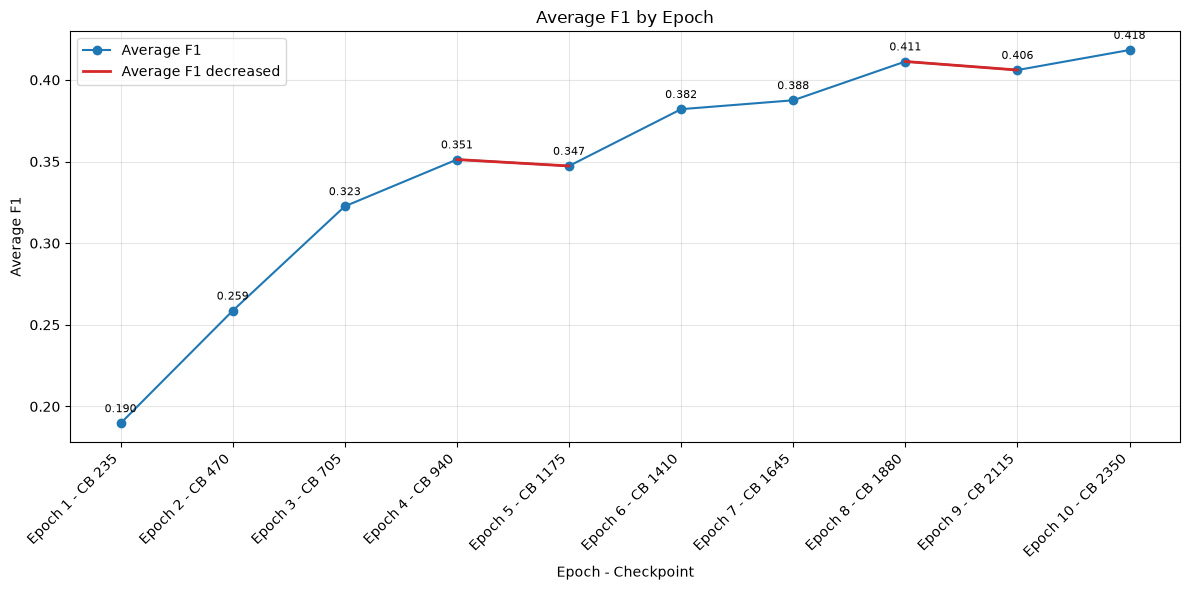

In [11]:
fig, ax = plot_checkpoint_scores(score_list)